In [1]:
# 1. Setup
!pip -q install xgboost
import warnings, json, os
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBClassifier, XGBRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score)
SEED = 42
os.makedirs('outputs', exist_ok=True)
sns.set_theme(style='whitegrid')

In [2]:
# 2. Load data (IBM HR Analytics Employee Attrition dataset)
URL = 'https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv'
try:
    df = pd.read_csv(URL, encoding='utf-8-sig')
except Exception as e:
    print('Download failed, please upload the CSV manually:', e)
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(list(up.keys())[0], encoding='utf-8-sig')
print(df.shape)
df.head()

(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 3. Exploratory Data Analysis

In [3]:
print(df.info())
print('\nMissing values:', df.isna().sum().sum())
print('\nAttrition counts:\n', df['Attrition'].value_counts())
print('Attrition rate: %.1f%%' % (100*(df['Attrition']=='Yes').mean()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

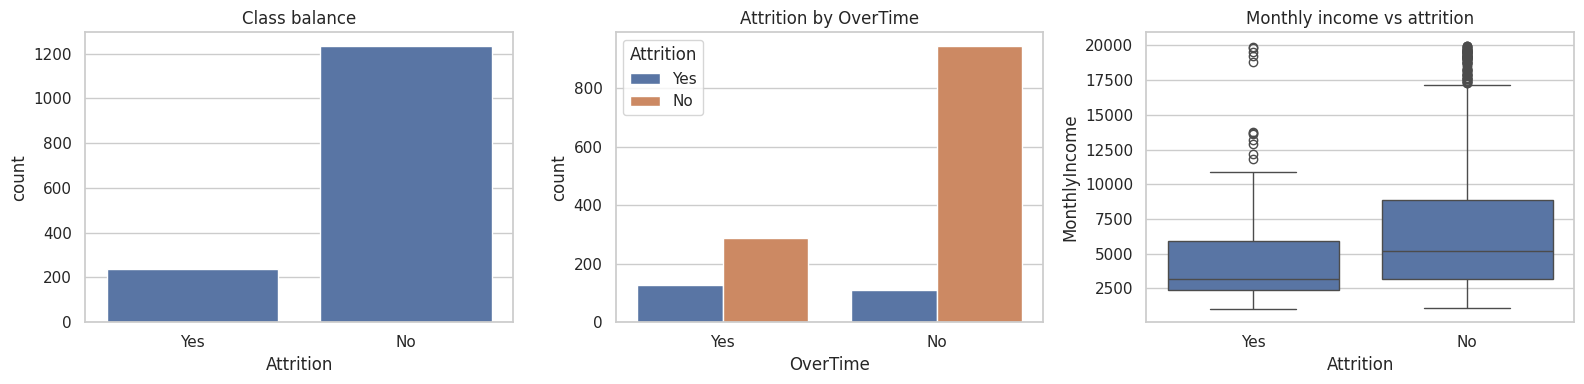

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x='Attrition', data=df, ax=ax[0]); ax[0].set_title('Class balance')
sns.countplot(x='OverTime', hue='Attrition', data=df, ax=ax[1]); ax[1].set_title('Attrition by OverTime')
sns.boxplot(x='Attrition', y='MonthlyIncome', data=df, ax=ax[2]); ax[2].set_title('Monthly income vs attrition')
plt.tight_layout(); plt.savefig('outputs/eda.png', dpi=130); plt.show()

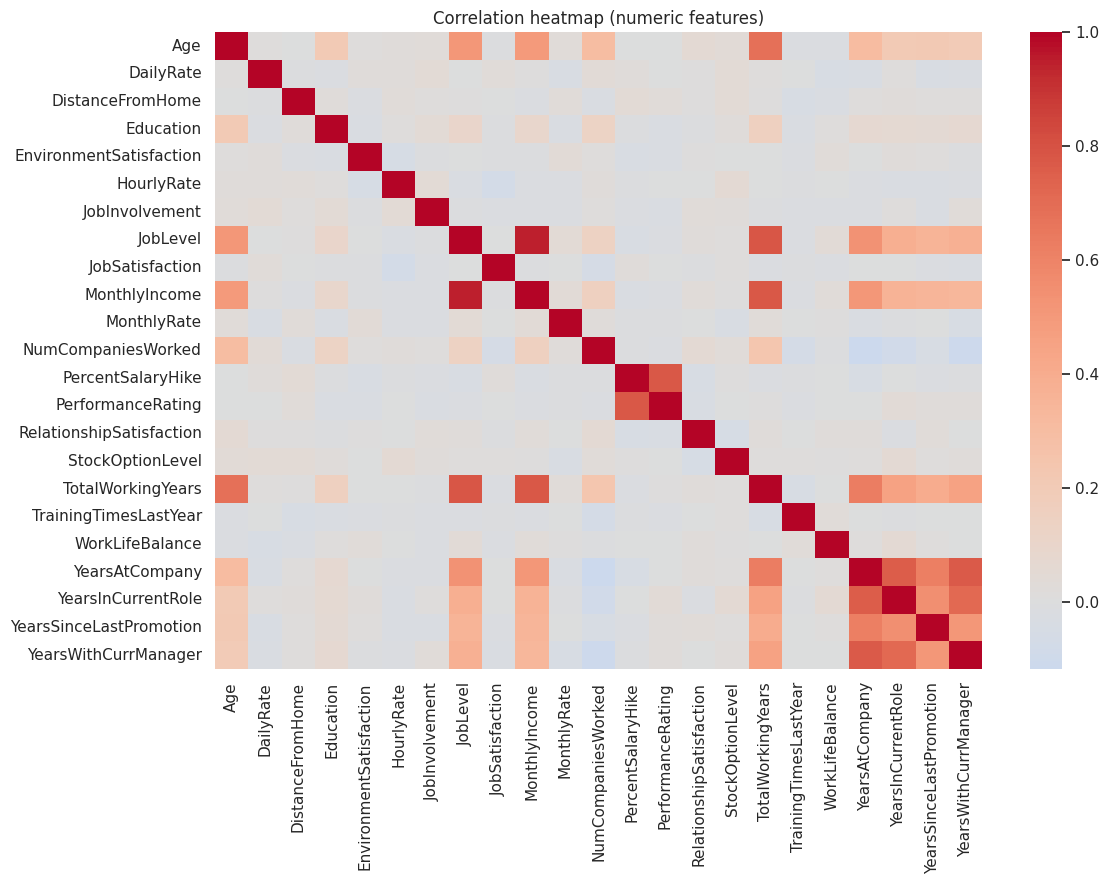

In [5]:
num = df.select_dtypes('number').drop(columns=['EmployeeCount','EmployeeNumber','StandardHours'])
plt.figure(figsize=(12, 9)); sns.heatmap(num.corr(), cmap='coolwarm', center=0)
plt.title('Correlation heatmap (numeric features)'); plt.tight_layout()
plt.savefig('outputs/corr.png', dpi=130); plt.show()

## 4. Preprocessing
- Drop constant / ID columns (`EmployeeCount`, `EmployeeNumber`, `StandardHours`, `Over18`)
- Encode target (`Yes`→1, `No`→0)
- One-hot encode categorical columns, scale numeric columns (inside a pipeline → no data leakage)

In [6]:
drop_cols = [c for c in ['EmployeeCount','EmployeeNumber','StandardHours','Over18'] if c in df.columns]
data = df.drop(columns=drop_cols).copy()
y = (data['Attrition'] == 'Yes').astype(int)
X = data.drop(columns=['Attrition'])

cat_cols = X.select_dtypes(exclude='number').columns.tolist()
num_cols = X.select_dtypes(include='number').columns.tolist()
print('Categorical:', cat_cols)
print('Numeric count:', len(num_cols))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape, y_train.mean().round(3), y_test.mean().round(3))

def make_pre(scale=True):
    return ColumnTransformer([
        ('num', StandardScaler() if scale else 'passthrough', num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)])

Categorical: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Numeric count: 23
(1176, 30) (294, 30) 0.162 0.16


## 5. Baseline classification models

In [8]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    'Logistic Regression': Pipeline([('pre', make_pre(True)),
        ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED))]),
    'Decision Tree': Pipeline([('pre', make_pre(False)),
        ('clf', DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=SEED))]),
    'Random Forest': Pipeline([('pre', make_pre(False)),
        ('clf', RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED, n_jobs=-1))]),
    'XGBoost': Pipeline([('pre', make_pre(False)),
        ('clf', XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, scale_pos_weight=pos_weight,
                              eval_metric='logloss', random_state=SEED, n_jobs=-1))]),
}

def evaluate(model, Xt, yt):
    pred = model.predict(Xt); proba = model.predict_proba(Xt)[:, 1]
    return {'Accuracy': accuracy_score(yt, pred), 'Precision': precision_score(yt, pred, zero_division=0),
            'Recall': recall_score(yt, pred), 'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, proba)}

rows = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    rows[name] = evaluate(m, X_test, y_test)
baseline = pd.DataFrame(rows).T.round(3)
baseline.to_csv('outputs/baseline_metrics.csv')
baseline

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.752,0.349,0.638,0.451,0.803
Decision Tree,0.786,0.379,0.532,0.442,0.653
Random Forest,0.847,0.625,0.106,0.182,0.791
XGBoost,0.840,0.500,0.404,0.447,0.774


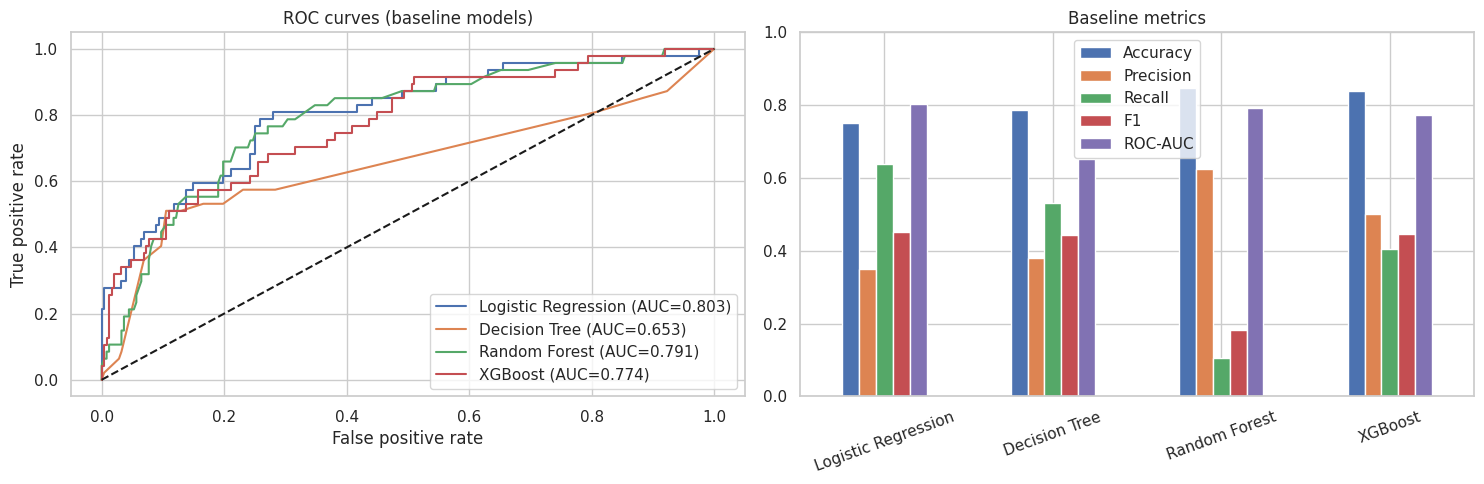

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for name, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={rows[name]['ROC-AUC']:.3f})")
ax[0].plot([0,1],[0,1],'k--'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate')
ax[0].set_title('ROC curves (baseline models)'); ax[0].legend()
baseline.plot(kind='bar', ax=ax[1]); ax[1].set_title('Baseline metrics'); ax[1].set_ylim(0, 1)
plt.xticks(rotation=20); plt.tight_layout(); plt.savefig('outputs/baseline_roc.png', dpi=130); plt.show()

## 6. 5-fold stratified cross-validation (baseline models)

In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1','roc_auc':'roc_auc'}
cv_rows = {}
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=skf, scoring=scoring, n_jobs=-1)
    cv_rows[name] = {k.replace('test_',''): f"{v.mean():.3f} ± {v.std():.3f}" for k, v in r.items() if k.startswith('test_')}
cv_table = pd.DataFrame(cv_rows).T
cv_table.to_csv('outputs/cv_metrics.csv'); cv_table

,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.753 ± 0.031,0.372 ± 0.038,0.737 ± 0.062,0.492 ± 0.034,0.827 ± 0.028
Decision Tree,0.697 ± 0.039,0.262 ± 0.030,0.468 ± 0.087,0.332 ± 0.036,0.627 ± 0.047
Random Forest,0.861 ± 0.007,0.870 ± 0.108,0.174 ± 0.057,0.284 ± 0.078,0.800 ± 0.027
XGBoost,0.871 ± 0.018,0.638 ± 0.074,0.458 ± 0.077,0.532 ± 0.076,0.796 ± 0.033


## 7. Hyperparameter tuning (GridSearchCV, optimising ROC-AUC)

In [11]:
grids = {
    'Logistic Regression': {'clf__C': [0.01, 0.1, 1, 10]},
    'Decision Tree': {'clf__max_depth': [3, 4, 5, 7], 'clf__min_samples_leaf': [5, 10, 20]},
    'Random Forest': {'clf__n_estimators': [200, 400], 'clf__max_depth': [6, 10, None], 'clf__min_samples_leaf': [1, 3, 5]},
    'XGBoost': {'clf__n_estimators': [200, 400], 'clf__max_depth': [3, 4, 5], 'clf__learning_rate': [0.03, 0.1]},
}
tuned, tuned_rows, best_params = {}, {}, {}
for name, m in models.items():
    gs = GridSearchCV(m, grids[name], cv=skf, scoring='roc_auc', n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_; best_params[name] = gs.best_params_
    tuned_rows[name] = evaluate(gs.best_estimator_, X_test, y_test)
    print(name, '| best CV AUC = %.3f' % gs.best_score_, '|', gs.best_params_)
tuned_df = pd.DataFrame(tuned_rows).T.round(3)
tuned_df.to_csv('outputs/tuned_metrics.csv'); tuned_df

Logistic Regression | best CV AUC = 0.831 | {'clf__C': 0.1}
Decision Tree | best CV AUC = 0.724 | {'clf__max_depth': 4, 'clf__min_samples_leaf': 10}
Random Forest | best CV AUC = 0.810 | {'clf__max_depth': None, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 400}
XGBoost | best CV AUC = 0.802 | {'clf__learning_rate': 0.03, 'clf__max_depth': 4, 'clf__n_estimators': 200}


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.772,0.381,0.681,0.489,0.812
Decision Tree,0.728,0.301,0.532,0.385,0.704
Random Forest,0.833,0.462,0.255,0.329,0.798
XGBoost,0.816,0.429,0.447,0.438,0.756


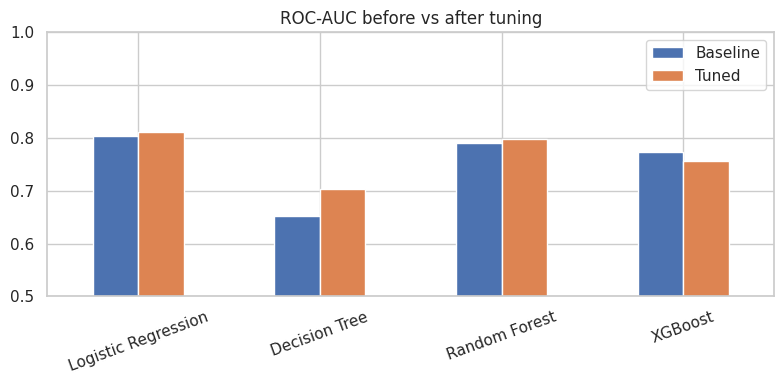

Best model by ROC-AUC: Logistic Regression


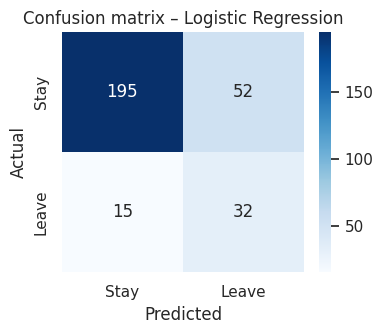

In [12]:
compare = pd.concat({'Baseline': baseline['ROC-AUC'], 'Tuned': tuned_df['ROC-AUC']}, axis=1)
compare.plot(kind='bar', figsize=(8,4)); plt.title('ROC-AUC before vs after tuning'); plt.ylim(0.5, 1)
plt.xticks(rotation=20); plt.tight_layout(); plt.savefig('outputs/tuning_compare.png', dpi=130); plt.show()

best_name = tuned_df['ROC-AUC'].idxmax(); print('Best model by ROC-AUC:', best_name)
best_model = tuned[best_name]
cm = confusion_matrix(y_test, best_model.predict(X_test))
plt.figure(figsize=(4,3.5)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Stay','Leave'], yticklabels=['Stay','Leave'])
plt.title(f'Confusion matrix – {best_name}'); plt.ylabel('Actual'); plt.xlabel('Predicted'); plt.tight_layout()
plt.savefig('outputs/confusion.png', dpi=130); plt.show()

## 8. Feature importance

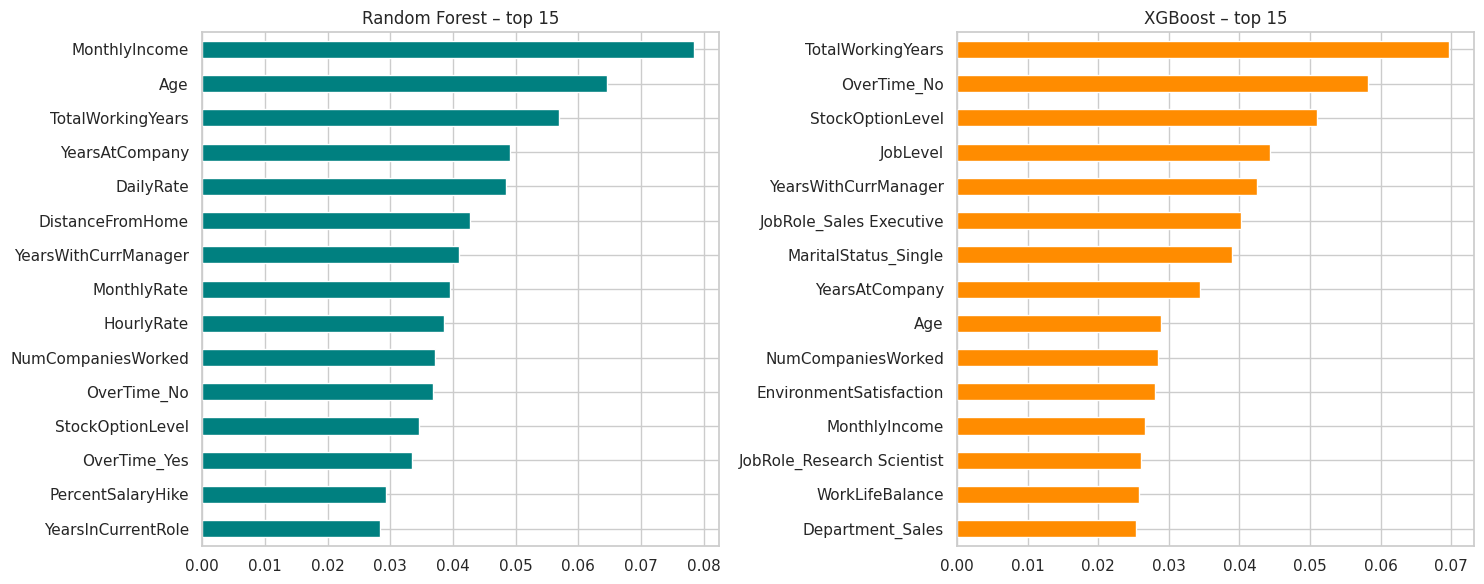

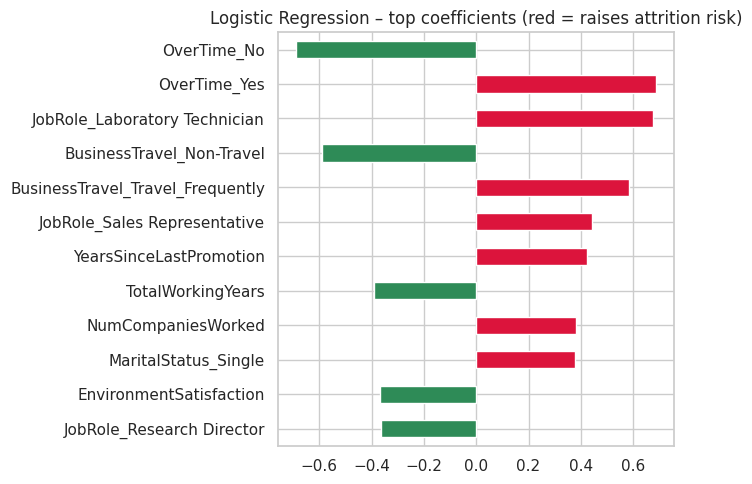

In [13]:
def feat_names(pipe):
    return pipe.named_steps['pre'].get_feature_names_out()

rf = tuned['Random Forest']; xgb = tuned['XGBoost']
imp_rf = pd.Series(rf.named_steps['clf'].feature_importances_, index=feat_names(rf)).sort_values(ascending=False).head(15)
imp_xgb = pd.Series(xgb.named_steps['clf'].feature_importances_, index=feat_names(xgb)).sort_values(ascending=False).head(15)
clean = lambda s: s.rename(lambda x: x.replace('num__','').replace('cat__',''))
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
clean(imp_rf)[::-1].plot(kind='barh', ax=ax[0], color='teal'); ax[0].set_title('Random Forest – top 15')
clean(imp_xgb)[::-1].plot(kind='barh', ax=ax[1], color='darkorange'); ax[1].set_title('XGBoost – top 15')
plt.tight_layout(); plt.savefig('outputs/feature_importance.png', dpi=130); plt.show()

lr = tuned['Logistic Regression']
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=feat_names(lr))
coef_top = clean(coef.reindex(coef.abs().sort_values(ascending=False).head(12).index))
coef_top[::-1].plot(kind='barh', figsize=(7,5), color=np.where(coef_top[::-1] > 0, 'crimson', 'seagreen'))
plt.title('Logistic Regression – top coefficients (red = raises attrition risk)'); plt.tight_layout()
plt.savefig('outputs/lr_coef.png', dpi=130); plt.show()
clean(imp_rf).to_csv('outputs/top_features_rf.csv'); clean(imp_xgb).to_csv('outputs/top_features_xgb.csv'); coef_top.to_csv('outputs/lr_top_coef.csv')

## 9. Regression (optional business task): predict **JobSatisfaction** (1–4)
Features: all columns except the target and `Attrition` (to avoid mixing the two tasks).

In [14]:
Xr = data.drop(columns=['JobSatisfaction', 'Attrition']); yr = data['JobSatisfaction']
cat_r = Xr.select_dtypes(exclude='number').columns.tolist(); num_r = Xr.select_dtypes(include='number').columns.tolist()
pre_r = lambda sc: ColumnTransformer([('num', StandardScaler() if sc else 'passthrough', num_r),
                                      ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_r)])
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.20, random_state=SEED)
reg_models = {
    'Linear Regression': Pipeline([('pre', pre_r(True)), ('m', LinearRegression())]),
    'Ridge': Pipeline([('pre', pre_r(True)), ('m', Ridge(alpha=10))]),
    'Random Forest Reg.': Pipeline([('pre', pre_r(False)), ('m', RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1))]),
    'XGBoost Reg.': Pipeline([('pre', pre_r(False)), ('m', XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=3, random_state=SEED))]),
}
kf = KFold(5, shuffle=True, random_state=SEED); reg_rows = {}
for n, m in reg_models.items():
    m.fit(Xr_tr, yr_tr); p = m.predict(Xr_te)
    cv_r2 = cross_validate(m, Xr_tr, yr_tr, cv=kf, scoring='r2')['test_score'].mean()
    reg_rows[n] = {'MAE': mean_absolute_error(yr_te, p), 'RMSE': np.sqrt(mean_squared_error(yr_te, p)),
                   'R2 (test)': r2_score(yr_te, p), 'R2 (5-fold CV)': cv_r2}
reg_df = pd.DataFrame(reg_rows).T.round(3); reg_df.to_csv('outputs/regression_metrics.csv')
print('Baseline (always predict mean) MAE: %.3f' % mean_absolute_error(yr_te, np.full(len(yr_te), yr_tr.mean())))
reg_df

Baseline (always predict mean) MAE: 0.970


,MAE,RMSE,R2 (test),R2 (5-fold CV)
Linear Regression,0.975,1.155,-0.054,-0.056
Ridge,0.973,1.151,-0.049,-0.049
Random Forest Reg.,0.969,1.138,-0.025,-0.042
XGBoost Reg.,0.987,1.158,-0.061,-0.106


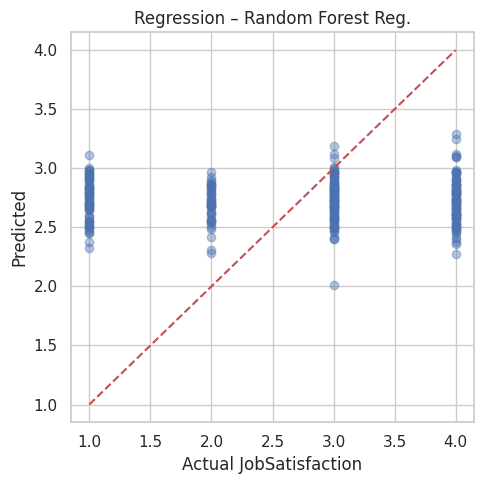

In [15]:
best_reg = reg_df['R2 (test)'].idxmax(); p = reg_models[best_reg].predict(Xr_te)
plt.figure(figsize=(5,5)); plt.scatter(yr_te, p, alpha=0.4); plt.plot([1,4],[1,4],'r--')
plt.xlabel('Actual JobSatisfaction'); plt.ylabel('Predicted'); plt.title(f'Regression – {best_reg}')
plt.tight_layout(); plt.savefig('outputs/regression_scatter.png', dpi=130); plt.show()

## 10. Save summary for the report

In [16]:
summary = {'best_classifier': best_name, 'best_params': {k: {a: (None if b is None else (b if isinstance(b,(int,float,str)) else str(b))) for a,b in v.items()} for k, v in best_params.items()},
           'baseline': baseline.to_dict('index'), 'tuned': tuned_df.to_dict('index'), 'regression': reg_df.to_dict('index'),
           'best_regressor': best_reg, 'n_rows': int(len(df)), 'attrition_rate': float(y.mean())}
json.dump(summary, open('outputs/summary.json', 'w'), indent=2)
print(json.dumps(summary['tuned'], indent=1))

{
 "Logistic Regression": {
  "Accuracy": 0.772,
  "Precision": 0.381,
  "Recall": 0.681,
  "F1": 0.489,
  "ROC-AUC": 0.812
 },
 "Decision Tree": {
  "Accuracy": 0.728,
  "Precision": 0.301,
  "Recall": 0.532,
  "F1": 0.385,
  "ROC-AUC": 0.704
 },
 "Random Forest": {
  "Accuracy": 0.833,
  "Precision": 0.462,
  "Recall": 0.255,
  "F1": 0.329,
  "ROC-AUC": 0.798
 },
 "XGBoost": {
  "Accuracy": 0.816,
  "Precision": 0.429,
  "Recall": 0.447,
  "F1": 0.438,
  "ROC-AUC": 0.756
 }
}
